In [52]:
import pandas as pd


In [53]:
df=pd.read_csv('knn_used_car_buyer_500.csv')
cdf=df.copy()

In [54]:
cdf.head()

,Age,Annual_Income,Credit_Score,Years_Experience,Car_Age,Car_Price,Previous_Car_Owned,Loan_Approved,Target
0,59,301934,572,39,6,1333316,1,0,Not Buy
1,49,675523,612,22,5,1169049,0,0,Not Buy
2,35,1090530,692,14,5,924771,0,1,Buy
3,28,1752713,702,1,4,823886,0,1,Buy
4,41,255486,694,19,5,1583203,0,1,Not Buy


In [55]:
cdf.shape

(500, 9)

In [56]:
cdf['Target']=cdf.Target.replace({
    'Not Buy':'0',
    'Buy':'1'
}).astype('int')

In [57]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 500 non-null    int64
 1   Annual_Income       500 non-null    int64
 2   Credit_Score        500 non-null    int64
 3   Years_Experience    500 non-null    int64
 4   Car_Age             500 non-null    int64
 5   Car_Price           500 non-null    int64
 6   Previous_Car_Owned  500 non-null    int64
 7   Loan_Approved       500 non-null    int64
 8   Target              500 non-null    int64
dtypes: int64(9)
memory usage: 35.3 KB


In [58]:
cdf.describe()

,Age,Annual_Income,Credit_Score,Years_Experience,Car_Age,Car_Price,Previous_Car_Owned,Loan_Approved,Target
count,500.000000,5.000000e+02,500.000000,500.000000,500.000000,5.000000e+02,500.000000,500.000000,500.000000
mean,41.436000,1.023749e+06,699.174000,16.916000,4.798000,1.059028e+06,0.424000,0.606000,0.690000
std,11.656142,4.409880e+05,87.568901,11.503286,3.037705,4.366438e+05,0.494685,0.489124,0.462956
min,21.000000,2.504040e+05,550.000000,0.000000,0.000000,3.075310e+05,0.000000,0.000000,0.000000
25%,32.000000,6.520430e+05,623.500000,6.000000,2.000000,7.048718e+05,0.000000,0.000000,0.000000
50%,43.000000,1.037877e+06,701.000000,18.000000,5.000000,1.053904e+06,0.000000,1.000000,1.000000
75%,52.000000,1.412515e+06,775.000000,27.000000,7.000000,1.444336e+06,1.000000,1.000000,1.000000
max,60.000000,1.791310e+06,850.000000,40.000000,10.000000,1.799118e+06,1.000000,1.000000,1.000000


In [59]:
cdf.isna().sum()

Age                   0
Annual_Income         0
Credit_Score          0
Years_Experience      0
Car_Age               0
Car_Price             0
Previous_Car_Owned    0
Loan_Approved         0
Target                0
dtype: int64

In [60]:
cdf.duplicated().sum()

np.int64(0)

***EDA***

Text(0.5, 1.0, 'Distribution of Age')

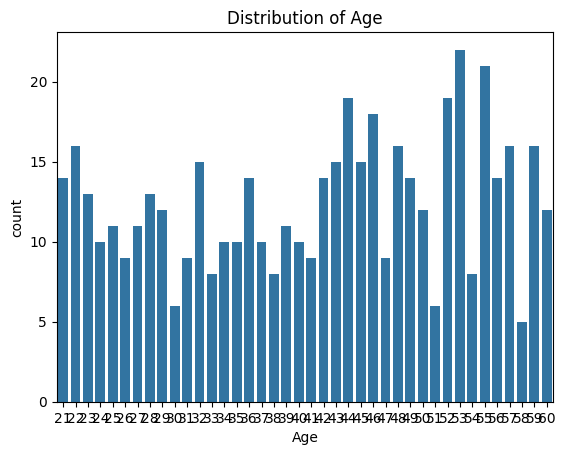

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=cdf,x='Age')
plt.title("Distribution of Age")


<Axes: xlabel='Car_Age', ylabel='Car_Price'>

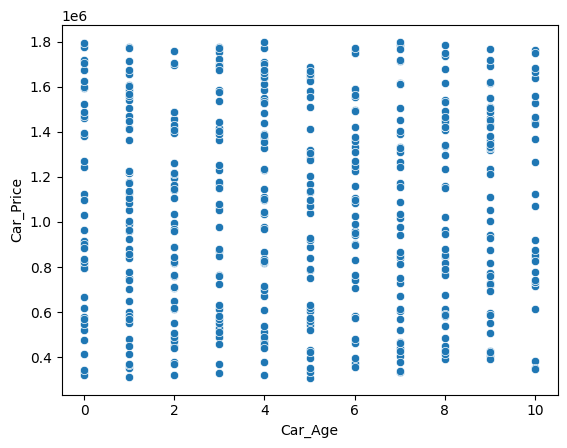

In [62]:
sns.scatterplot(data=cdf,x='Car_Age',y='Car_Price')

In [71]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,accuracy_score,f1_score,classification_report
X=cdf.drop(['Target'],axis=1)
Y=cdf.Target

x_train,x_test,y_train,y_test=train_test_split(X,Y,random_state=42,stratify=Y,test_size=0.20)
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.fit_transform(x_test)
model=KNeighborsClassifier(n_neighbors=2)
model.fit(x_train,y_train)

,n_neighbors,2
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [70]:
y_pred=model.predict(x_test)
print('MAE :',mean_squared_error(y_test,y_pred))
print('MSE :',mean_squared_error(y_test,y_pred))
print('Accuracy :',accuracy_score(y_test,y_pred))

MAE : 0.26
MSE : 0.26
Accuracy : 0.74


***USING GRID SEARCH CV***

In [65]:
from sklearn.model_selection import GridSearchCV

pipeline=Pipeline([
    ('scaler',StandardScaler()),
    ('Kmodel',KNeighborsClassifier())
])

param_grid={
    'Kmodel__n_neighbors':list(range(1,15))
}

grid=GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

grid.fit(x_train,y_train)


,estimator,Pipeline(step...lassifier())])
,param_grid,"{'Kmodel__n_neighbors': [1, 2, ...]}"
,scoring,'accuracy'
,n_jobs,1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [73]:
print('Best accuracy :',grid.best_score_)
print('Best Parameter :',grid.best_params_)
print('Best Estimator :',grid.best_estimator_)
bestmodel=grid.best_estimator_

best_y_pred=bestmodel.predict(x_test)

Best accuracy : 0.82
Best Parameter : {'Kmodel__n_neighbors': 11}
Best Estimator : Pipeline(steps=[('scaler', StandardScaler()),
                ('Kmodel', KNeighborsClassifier(n_neighbors=11))])


In [77]:

print("CLASSIFICATION REPORT OF BASE MODEL\n")
print(classification_report(y_test,y_pred))
print('-'*80)
print('\nCLASSIFICATION REPORT OF BEST MODEL\n')
print(classification_report(y_test,best_y_pred))

CLASSIFICATION REPORT OF BASE MODEL

              precision    recall  f1-score   support

           0       0.56      0.77      0.65        31
           1       0.88      0.72      0.79        69

    accuracy                           0.74       100
   macro avg       0.72      0.75      0.72       100
weighted avg       0.78      0.74      0.75       100

--------------------------------------------------------------------------------

CLASSIFICATION REPORT OF BEST MODEL

              precision    recall  f1-score   support

           0       0.70      0.61      0.66        31
           1       0.84      0.88      0.86        69

    accuracy                           0.80       100
   macro avg       0.77      0.75      0.76       100
weighted avg       0.79      0.80      0.80       100



In [78]:
new_data=pd.DataFrame({
    'Age':[29],
    'Annual_Income':[900000],
    'Credit_Score':[760],
    'Years_Experience':[6],
    'Car_Age':[2],
    'Car_Price':[750000],
    'Previous_Car_Owned':[0],
    'Loan_Approved':[1]
})

In [87]:
prediction=bestmodel.predict(new_data)

if (int)(prediction[0]==1):
    print('Buy')
else:
    print('Not Buy')

Buy


c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
